# Next Word Prediction using RNN and LSTM

Train a **SimpleRNN** and an **LSTM** on a text file, **compare them**, then give a starting text and the number of words you want. The model generates the rest automatically.

| Section | Content |
|---|---|
| 1-2 | Imports, load and clean text |
| 3-5 | Tokenizer, n-gram sequences, padding, X / y |
| 6 | Model builder (SimpleRNN or LSTM) |
| 7 | Train both and compare |
| 8 | Top-k next word suggestions (like a phone keyboard) |
| 9 | Text generation (greedy and temperature sampling) |
| 10 | Your own input: seed text + number of words |
| 11 | Save model and tokenizer |

Theory: see `docs/RNN_and_LSTM_Explained.md`. Code explanation: `docs/CODE_WALKTHROUGH.md`.

## 1. Imports and reproducibility

In [1]:
import os, re, json, time
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"          # hide TensorFlow info logs

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, LSTM, Dense
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Load the text file and split into sentences
Sentences are split after `.`, `?` or `!` followed by a space. The path works whether you run from the repo root or from `notebooks/`.

In [2]:
def find_path(*candidates):
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"None of these paths exist: {candidates}")

def file_to_sentence_list(file_path):
    with open(file_path, 'r', encoding='utf-8') as f:
        text = f.read()
    return [s.strip() for s in re.split(r'(?<=[.!?])\s+', text) if s.strip()]

DATA_PATH = find_path('data/pizza.txt', '../data/pizza.txt')   # or your own file, e.g. 'c:/data/pizza.txt'
ROOT      = '.' if os.path.isdir('data') else '..'
IMG_DIR, MODEL_DIR = f'{ROOT}/images', f'{ROOT}/models'

text_data = file_to_sentence_list(DATA_PATH)
print("Total sentences:", len(text_data))
text_data[:2]

Total sentences: 79


['Pizza, the delectable and iconic dish that has transcended borders and captivated taste buds worldwide, is a testament to the extraordinary fusion of flavors, creativity, and cultural significance.',
 'Originating from the sun-kissed lands of Italy, pizza has evolved into an art form that unites people from diverse backgrounds in a shared love for its mouthwatering combinations.']

## 3. Tokenizer: words to integers
`fit_on_texts` builds the vocabulary (most frequent word = 1). `+ 1` because index 0 is reserved for padding.

In [3]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts(text_data)
total_words = len(tokenizer.word_index) + 1
print("Vocabulary size (total_words):", total_words)
list(tokenizer.word_index.items())[:10]

Vocabulary size (total_words): 687


[('the', 1),
 ('and', 2),
 ('pizza', 3),
 ('of', 4),
 ('a', 5),
 ('to', 6),
 ('in', 7),
 ('has', 8),
 ('its', 9),
 ('for', 10)]

## 4. N-gram sequences
Each prefix of a sentence becomes one training example. In `[1, 5, 2, 39]` the last number is the **word to predict**, the numbers before it are the **context**.

In [4]:
input_sequences = []
for line in text_data:
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        input_sequences.append(token_list[:i + 1])

print("Total training sequences:", len(input_sequences))
input_sequences[:5]

Total training sequences: 1628


[[3, 1],
 [3, 1, 233],
 [3, 1, 233, 2],
 [3, 1, 233, 2, 45],
 [3, 1, 233, 2, 45, 35]]

## 5. Pad and split into X and y
`padding='pre'` puts zeros at the start so the most recent word is next to the output. `y` is one-hot encoded for `categorical_crossentropy`.

In [5]:
max_sequence_len = max(len(seq) for seq in input_sequences)
input_sequences = np.array(pad_sequences(input_sequences, maxlen=max_sequence_len, padding='pre'))

X, y = input_sequences[:, :-1], input_sequences[:, -1]
y = tf.keras.utils.to_categorical(y, num_classes=total_words)

print("max_sequence_len:", max_sequence_len)
print("X shape:", X.shape, "| y shape:", y.shape)

max_sequence_len: 40
X shape: (1628, 39) | y shape: (1628, 687)


## 6. Model builder
`Embedding -> (SimpleRNN | LSTM) -> Dense(softmax)`

| Layer | Parameters |
|---|---|
| Embedding | `total_words x EMBED_DIM` |
| SimpleRNN | `UNITS x (EMBED_DIM + UNITS + 1)` |
| LSTM | `4 x UNITS x (EMBED_DIM + UNITS + 1)` (4 gates) |
| Dense | `UNITS x total_words + total_words` |

In [6]:
EMBED_DIM, UNITS = 10, 128

def build_model(cell='lstm'):
    rnn_layer = LSTM(UNITS) if cell == 'lstm' else SimpleRNN(UNITS)
    model = Sequential([
        Input(shape=(max_sequence_len - 1,)),
        Embedding(total_words, EMBED_DIM),
        rnn_layer,
        Dense(total_words, activation='softmax'),
    ], name=f"{cell}_next_word")
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

build_model('lstm').summary()

Model: "lstm_next_word"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 39, 10)         │         6,870 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │        71,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 687)            │        88,623 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 166,661 (651.02 KB)

 Trainable params: 166,661 (651.02 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Train both models and compare
Same data, same epochs, same units. Only the recurrent cell changes.

In [7]:
EPOCHS = 200
models, histories, results = {}, {}, []

for cell in ['rnn', 'lstm']:
    tf.keras.backend.clear_session(); tf.random.set_seed(SEED)
    m = build_model(cell)
    t0 = time.time()
    h = m.fit(X, y, epochs=EPOCHS, batch_size=32, verbose=0)
    models[cell], histories[cell] = m, h.history
    results.append((cell.upper(), m.count_params(), h.history['loss'][-1], h.history['accuracy'][-1], time.time() - t0))

print(f"{'Model':<6} {'Params':>9} {'Final loss':>11} {'Final acc':>10} {'Time (s)':>9}")
for name, params, loss, acc, sec in results:
    print(f"{name:<6} {params:>9,} {loss:>11.4f} {acc:>10.4f} {sec:>9.1f}")

Model     Params  Final loss  Final acc  Time (s)
RNN      113,285      0.0789     0.9650     108.1
LSTM     166,661      0.1231     0.9631     236.6


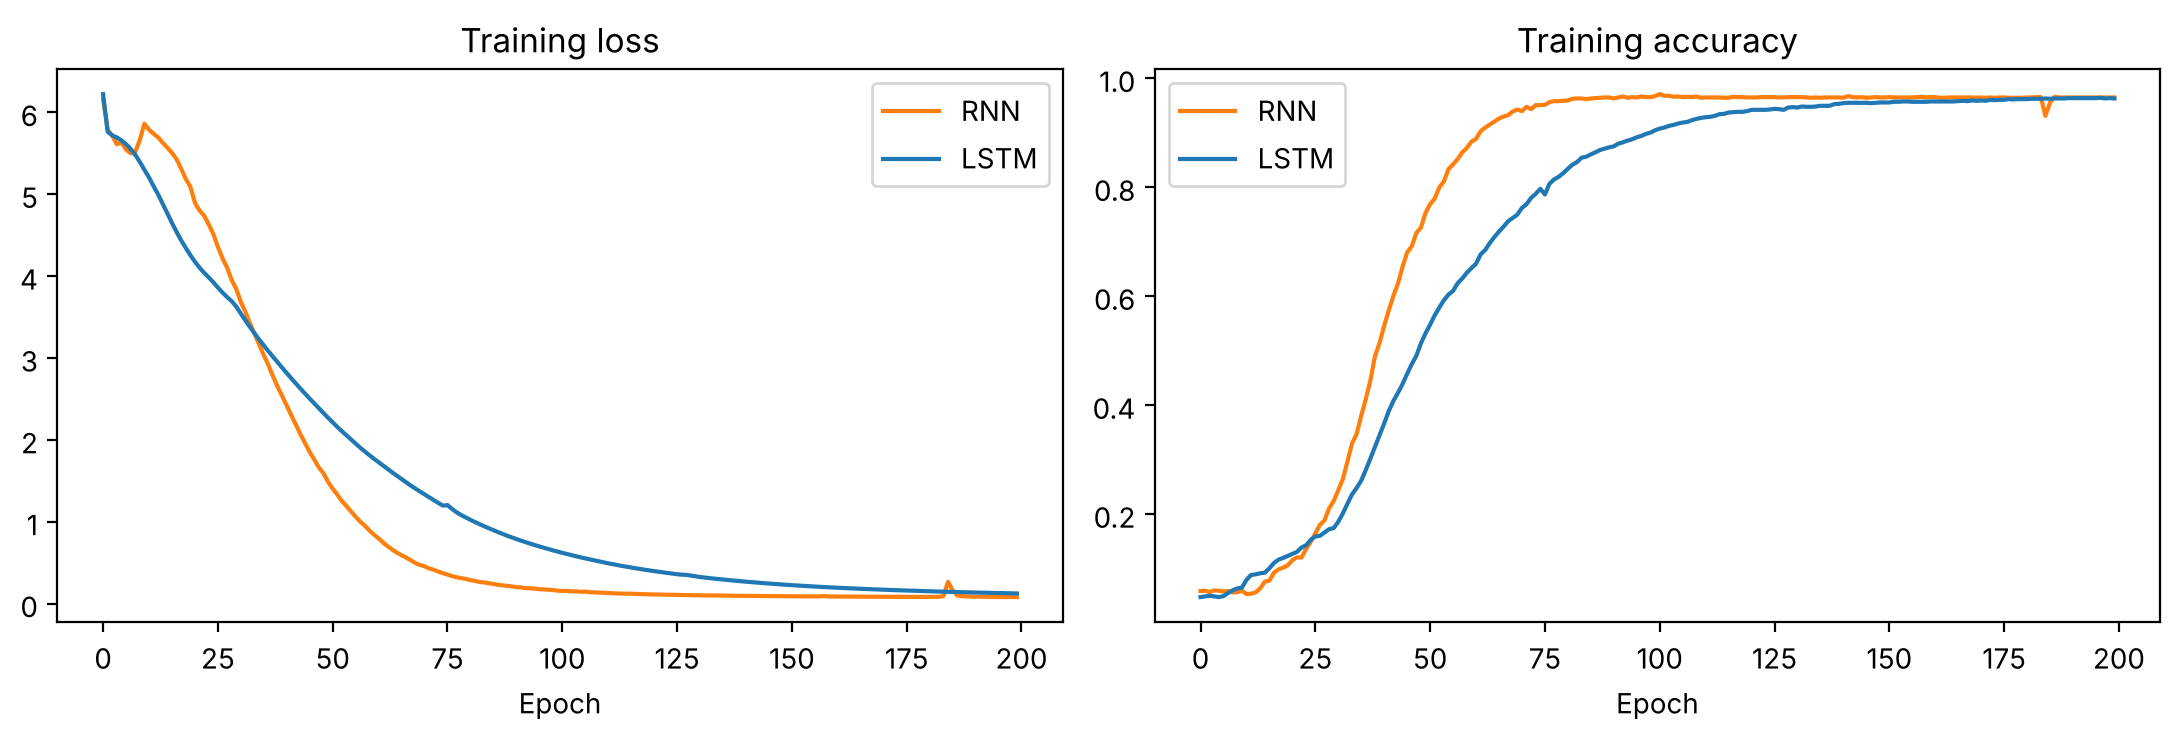

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for cell, color in [('rnn', 'tab:orange'), ('lstm', 'tab:blue')]:
    ax[0].plot(histories[cell]['loss'], label=cell.upper(), color=color)
    ax[1].plot(histories[cell]['accuracy'], label=cell.upper(), color=color)
ax[0].set_title('Training loss');     ax[0].set_xlabel('Epoch'); ax[0].legend()
ax[1].set_title('Training accuracy'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/training_comparison.png', dpi=130)
plt.show()

## 8. Top-k next word suggestions
Like a phone keyboard: show the most likely next words with their probabilities.

In [9]:
def predict_top_k(text, k=5, model=None):
    model = model or models['lstm']
    tokens = tokenizer.texts_to_sequences([text])[0]
    if not tokens:
        return []
    tokens = pad_sequences([tokens], maxlen=max_sequence_len - 1, padding='pre')
    probs = model.predict(tokens, verbose=0)[0]
    top = np.argsort(probs)[::-1][:k]
    return [(tokenizer.index_word.get(i, '?'), float(probs[i])) for i in top if i != 0]

for text in ["pizza is", "the crust", "many people"]:
    print(f"'{text}' ->", ", ".join(f"{w} ({p:.0%})" for w, p in predict_top_k(text)))

'pizza is' -> much (89%), and (4%), not (3%), a (1%), from (1%)
'the crust' -> of (99%), and (1%), in (0%), pizza (0%), from (0%)
'many people' -> and (93%), from (4%), of (2%), for (0%), in (0%)


## 9. Text generation
`generate_text(seed_text, next_words)` predicts one word, appends it, and repeats `next_words` times.

- `temperature=0` : always the most likely word (`argmax`). Can repeat words.
- `temperature>0` (e.g. `0.7`): samples from the probabilities, so the text is more varied.

In [10]:
def generate_text(seed_text, next_words, temperature=0.0, model=None):
    model = model or models['lstm']
    for _ in range(next_words):
        tokens = tokenizer.texts_to_sequences([seed_text])[0]
        if not tokens:
            print("None of the words are in the vocabulary. Try another start.")
            return seed_text
        tokens = pad_sequences([tokens], maxlen=max_sequence_len - 1, padding='pre')
        probs = model.predict(tokens, verbose=0)[0]

        if temperature > 0:
            p = np.exp(np.log(probs + 1e-9) / temperature)
            idx = np.random.choice(len(p), p=p / p.sum())
        else:
            idx = int(np.argmax(probs))

        word = tokenizer.index_word.get(idx, "")
        if not word:
            break
        seed_text += " " + word
    return seed_text

In [11]:
for seed in ["pizza is", "the crust", "many people"]:
    for cell in ['rnn', 'lstm']:
        print(f"[{cell.upper():<4}] {generate_text(seed, 12, model=models[cell])}")
    print()

[RNN ] pizza is much more than a delicious dish—it is a culinary phenomenon that has


[LSTM] pizza is much more than a delicious dish—it is a culinary phenomenon that has



[RNN ] the crust and wide availability of pizza have made it a staple at parties


[LSTM] the crust of global flavors will persist with innovative combinations that reflect the ever



[RNN ] many people variations pizza has embraced the growing demand for healthier options made pizza


[LSTM] many people and augmented reality may even enhance the dining experience allowing customers to



In [12]:
print("Temperature 0.7 (LSTM):")
for _ in range(3):
    print("  ", generate_text("pizza is", 12, temperature=0.7))

Temperature 0.7 (LSTM):


   pizza is much more than a delicious dish—it is a culinary phenomenon that has


   pizza is much more than a delicious dish—it is a culinary phenomenon that has


   pizza is much more than a delicious dish—it is a culinary phenomenon that has


## 10. Your own input: starting text + how many words
Type a starting text and the number of words. Type `q` to stop. If the notebook runs without a keyboard (server / Run All), a demo input is used.

In [13]:
try:
    while True:
        seed = input("Enter starting text (or q to quit): ").strip()
        if seed.lower() == 'q':
            break
        n = int(input("How many words to generate: "))
        print("\nGenerated:", generate_text(seed, n), "\n")
except Exception:
    print("Demo input -> seed: 'pizza is', words: 15")
    print("Generated:", generate_text("pizza is", 15))

Demo input -> seed: 'pizza is', words: 15


Generated: pizza is much more than a delicious dish—it is a culinary phenomenon that has captured the hearts


## 11. Save the model and tokenizer
So you can reuse them without training again (see `src/next_word_lstm.py`).

In [14]:
os.makedirs(MODEL_DIR, exist_ok=True)
models['lstm'].save(f'{MODEL_DIR}/lstm_next_word.keras')
with open(f'{MODEL_DIR}/tokenizer.json', 'w') as f:
    f.write(tokenizer.to_json())
json.dump({'max_sequence_len': int(max_sequence_len)}, open(f'{MODEL_DIR}/config.json', 'w'))
os.listdir(MODEL_DIR)

['.gitkeep', 'config.json', 'lstm_next_word.keras', 'tokenizer.json']

## Key takeaways

- A **SimpleRNN** has one hidden state and suffers from vanishing gradients on long sequences. An **LSTM** adds a cell state and 3 gates (forget, input, output) that decide what to keep, so it can learn longer context.
- The LSTM has **4x** the recurrent parameters of a SimpleRNN with the same number of units (71,168 vs 17,792 here).
- **In this experiment both reach about 96% training accuracy.** The text is small (about 1,700 words), so even a SimpleRNN can memorize it, and it trains about 2x faster. The LSTM's advantage shows up on longer text and bigger datasets.
- High training accuracy here means **memorization**, not good generalization. This is why temperature 0.7 still gives the same sentence: the model is almost certain about every next word it has seen.
- A word joined by a dash (for example `dish—it`) becomes **one token**. Replace `—` with a space before tokenizing for a cleaner vocabulary.
- Better results: much more text, a validation split, dropout, stacked or `Bidirectional` LSTM, or a pretrained language model.
- Exact numbers change slightly between runs because of random weight initialization.